In [2]:
# Install packages
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns

#Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
prescribed_burns_cleaned = gpd.read_file(processed_fldr / "prescribed_burns.gpkg")
inaturalist_gdf_cleaned = gpd.read_file(processed_fldr / "inaturalist_gdf_cleaned.gpkg")

In [3]:
#Check variable types and missing values
prescribed_burns_cleaned.info()
prescribed_burns_cleaned.isna().mean().sort_values()*100

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 11953 entries, 0 to 11952
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   year               11953 non-null  int64              
 1   agency             11953 non-null  str                
 2   burn_name          10485 non-null  str                
 3   treatment_type     9858 non-null   float64            
 4   start_date         10201 non-null  datetime64[ms, UTC]
 5   end_date           10001 non-null  datetime64[ms, UTC]
 6   acres_treated      11189 non-null  float64            
 7   gis_acres_treated  11951 non-null  float32            
 8   Shape_Length       11953 non-null  float64            
 9   Shape_Area         11953 non-null  float64            
 10  geometry           11953 non-null  geometry           
dtypes: datetime64[ms, UTC](2), float32(1), float64(4), geometry(1), int64(1), str(2)
memory usage: 980

year                  0.000000
agency                0.000000
Shape_Area            0.000000
Shape_Length          0.000000
geometry              0.000000
gis_acres_treated     0.016732
acres_treated         6.391701
burn_name            12.281436
start_date           14.657408
end_date             16.330628
treatment_type       17.526981
dtype: float64

Prescribed Fires Data Audit:
All data types are correct. All row entries have years and fire polygons, which are most important for analysis. Specific start date and end date are useful for getting better insight into the month and length of fires, but not necessarily vital for analysis. It would be interesting to look at the impacts of treatment type, but we will only be able to do this with ~85% of the records. There are no duplicate rows or implausible values, based on what we have observed. 

In [4]:
#Check variable types and missing values
inaturalist_gdf_cleaned.info()
inaturalist_gdf_cleaned.isna().mean().sort_values()*100

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 147426 entries, 0 to 147425
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   observation_date  147426 non-null  datetime64[ms]
 1   location          147230 non-null  str           
 2   scientific_name   147426 non-null  str           
 3   common_name       147426 non-null  str           
 4   geometry          147426 non-null  geometry      
dtypes: datetime64[ms](1), geometry(1), str(3)
memory usage: 5.6 MB


observation_date    0.000000
scientific_name     0.000000
common_name         0.000000
geometry            0.000000
location            0.132948
dtype: float64

Invasives Audit:

A join between these two datasets is not practical because they don't have matching columns and the rows represent entirely different things. For our main analysis, we plan to pull the geometries from both datasets separately to assess where they intersect (also taking date into consideration).

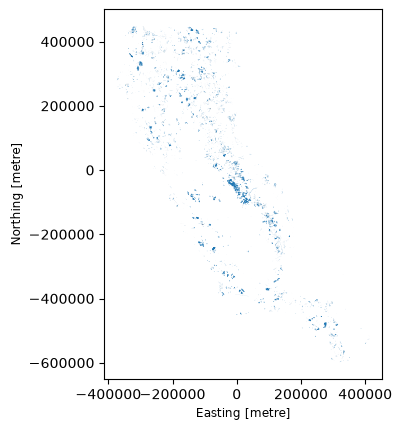

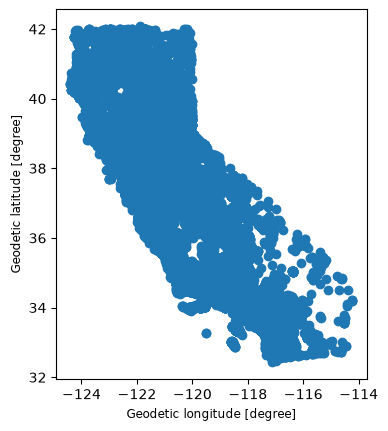

In [5]:
prescribed_burns_cleaned.plot();
inaturalist_gdf_cleaned.plot();

Preliminary exploratory analysis: map of prescribed fires